# Explaining term-deposit predictions with SHAP

This notebook explains the saved production classifier without fitting a new model. It uses **interventional TreeSHAP in probability space**, with the same training-only reference sample used by the API. Subscription (`deposit=1`) is the positive class.

Run cleaning and training first (see README), then select the project's Python 3.11 environment. Install `requirements-test.txt` to execute with `python scripts/execute_explanations.py`.

The background artifact is checked against the model and preprocessor. Only held-out rows recorded during that training run are analyzed; changing the cleaned dataset requires retraining.

In [1]:
import os
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from tqdm.std import TqdmWarning
# No widget progress bar is needed for this batch analysis.
warnings.filterwarnings("ignore", message="IProgress not found.*", category=TqdmWarning)
import shap

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/model_config.yaml').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.api.explanations import load_explainer
from src.features.engineer import create_features, to_dense_frame

MODEL_DIR = Path(os.environ.get('BANK_SHAP_MODEL_DIR', str(ROOT / 'models/trained')))
DATA_PATH = Path(os.environ.get('BANK_SHAP_DATA', str(ROOT / 'data/processed/cleaned_bank_data.csv')))
OUTPUT_DIR = Path(os.environ.get('BANK_SHAP_OUTPUT_DIR', str(ROOT / 'reports/figures/shap')))
SAMPLE_SIZE = int(os.environ.get('BANK_SHAP_SAMPLE_SIZE', '200'))
if SAMPLE_SIZE < 1:
    raise ValueError('SAMPLE_SIZE must be positive')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model_path, preprocessor_path = MODEL_DIR / 'bank_deposit_model.pkl', MODEL_DIR / 'preprocessor.pkl'
model, preprocessor = joblib.load(model_path), joblib.load(preprocessor_path)
explainer = load_explainer(model, preprocessor, model_path, preprocessor_path)
data = pd.read_csv(DATA_PATH)
assert joblib.hash(data) == explainer.bundle['dataset_hash'], 'Dataset changed: retrain before interpreting this model'
assert set(explainer.bundle['background_indices']).isdisjoint(explainer.bundle['test_indices'])
holdout = data.iloc[explainer.bundle['test_indices']]
sample = holdout.sample(n=min(SAMPLE_SIZE, len(holdout)), random_state=85).reset_index(drop=True)
featured = create_features(sample.drop(columns=['deposit']))
encoded = to_dense_frame(preprocessor.transform(featured), preprocessor)
base, grouped = explainer.explain(encoded)
probabilities = model.predict_proba(encoded)[:, 1]
np.testing.assert_allclose(base + grouped.sum(axis=1), probabilities, atol=1e-6, rtol=0)
print(f'Model: {type(model).__name__}; held-out rows explained: {len(sample)}')
print(f'Training reference rows: {len(explainer.bundle["background"])}; baseline probability: {base:.2%}')
print(f'Maximum reconstruction error: {np.max(np.abs(base + grouped.sum(axis=1) - probabilities)):.2e}')

2026-10-28 14:04:39,227 - bank-feature-engineering - INFO - Creating bank marketing features


Model: GradientBoostingClassifier; held-out rows explained: 200
Training reference rows: 100; baseline probability: 51.50%
Maximum reconstruction error: 7.17e-09


## Overall importance by original field

The plot reports mean absolute **grouped** SHAP contributions on the held-out sample, in percentage points. Encoded columns are summed within each original field before taking the absolute value. A high value means a large contribution to model scores, not a causal effect or a measure of predictive accuracy. Opposing encoded contributions can cancel within a field.

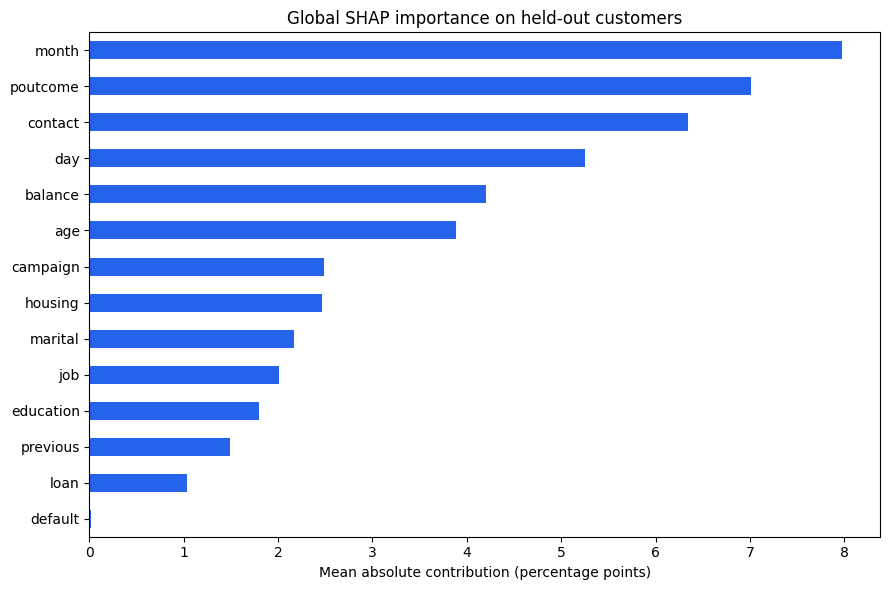

,Mean absolute contribution (pp)
month,7.980657
poutcome,7.015550
contact,6.342019
day,5.255088
balance,4.205035
age,3.886881
campaign,2.488638
housing,2.464364
marital,2.165879
job,2.009477


In [2]:
importance = grouped.abs().mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(9, 6))
importance.sort_values().plot.barh(ax=ax, color='#2563eb')
ax.set_xlabel('Mean absolute contribution (percentage points)')
ax.set_title('Global SHAP importance on held-out customers')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'global_importance.png', dpi=160)
plt.show()
plt.close(fig)
importance.rename('mean_absolute_contribution_pp').to_csv(OUTPUT_DIR / 'global_importance.csv')
importance.to_frame('Mean absolute contribution (pp)')

## Direction and spread of contributions

This beeswarm uses the **encoded features** so color retains a numeric meaning: blue is a lower feature value, red a higher value. For a dummy variable, 0 means absent and 1 means present. Each dot is a held-out customer. Left reduces the score; right increases it. The horizontal axis is probability units (0.10 = 10 percentage points).

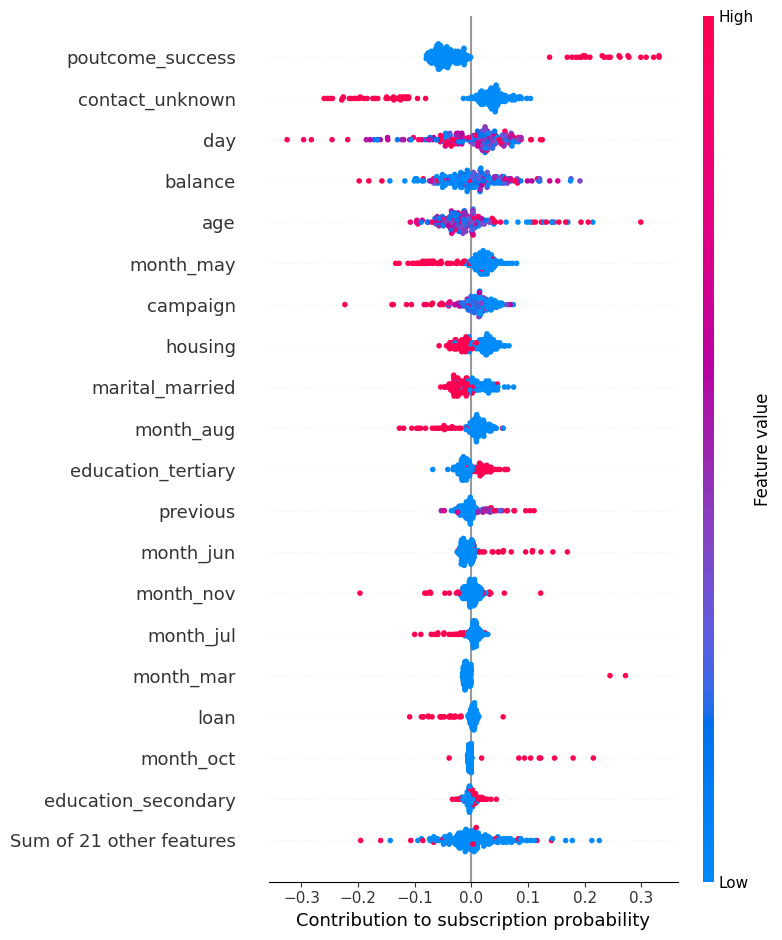

In [3]:
encoded_values = np.asarray(explainer.explainer.shap_values(encoded))
if encoded_values.ndim == 3:
    encoded_values = encoded_values[:, :, 1]
encoded_explanation = shap.Explanation(values=encoded_values,
    base_values=np.full(len(encoded), base), data=encoded.to_numpy(), feature_names=list(encoded.columns))
shap.plots.beeswarm(encoded_explanation, max_display=20, show=False)
plt.xlabel('Contribution to subscription probability')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'beeswarm.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close()

## One customer: baseline to prediction

The same grouped attributions appear in Streamlit. All input fields are retained so baseline + signed contributions reconstructs the score. The values displayed beside features below are the customer's original inputs.

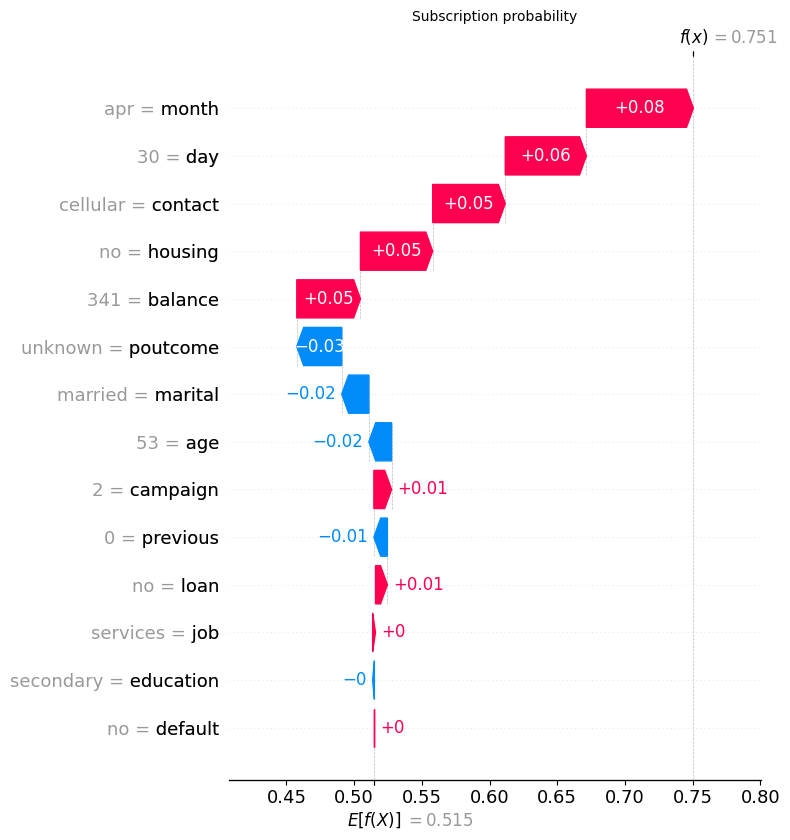

Customer score: 75.05%; observed subscription: 1


In [4]:
row = 0
local_explanation = shap.Explanation(values=grouped.iloc[row].to_numpy(), base_values=base,
    data=sample.loc[row, grouped.columns].to_numpy(), feature_names=list(grouped.columns))
shap.plots.waterfall(local_explanation, max_display=len(grouped.columns), show=False)
plt.xlabel('Subscription probability')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'customer_waterfall.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close()
print(f'Customer score: {probabilities[row]:.2%}; observed subscription: {int(sample.loc[row, "deposit"])}')

## Interpretation limits

- These are explanations of the fitted model, not reasons a person actually subscribes, fairness guarantees, or recommendations to change a customer's attributes.
- The baseline is the average model prediction on 100 (or fewer) sampled training rows, not the observed subscription rate or a calibrated population probability.
- Interventional SHAP depends on the reference sample and its assumptions about feature dependence. Correlated inputs and one-hot encoded variables can yield combinations outside the observed data. Summing encoded attributions makes them readable, but is not a separate grouped-feature Shapley computation.
- Global importance depends on the held-out sample. Increase `SAMPLE_SIZE` to analyze more rows; explanation time grows with sample and background sizes.
- `duration` and `pdays` remain excluded. No test rows are used to construct the reference distribution.

References: [TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html), [SHAP beeswarm](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/beeswarm.html).